# REE Positive Samples — Spatial Clustering & Radius-Based Deduplication (All Regions)

Each of the three study areas — **Cordilleran**, **Superior**, and **Grenville**
— has REE/carbonatite deposit points inside its outline, but several of them
sit within a kilometre or two of each other in every region — almost
certainly multiple records for the same deposit / mining district rather
than independent occurrences. Treating those as separate positive samples
double-counts a single spatial signal and can bias both the feature
selection (`select_negatives_mixed` centers on the positive centroid) and
the tiny-sample CV protocol used in `multiregion_rf_devnet_v3.ipynb`.

This notebook, for **all three regions**:

1. Loads the region's positives the same way `make_points()` does in the
   main modeling notebooks (REE deposits within each region's outline).
2. Loads a second, independent compilation (`Parsa_2024_REE_occurrences_fixed.csv`)
   and **combines it with the first** into one positive pool per region
   (`POS_IN`) — a `source` column tracks which dataset each point came from.
   Combining before deduplication matters: the same real-world deposit can
   appear in both datasets under different names, and only merging the two
   pools first lets the radius-based dedup below catch those cross-dataset
   duplicates too, not just within-dataset ones.
3. Visualizes the combined spatial distribution and nearest-neighbor
   distances to show how much near-duplication exists at different radii.
4. Deduplicates: any positives within `DEDUP_RADIUS_KM` of each other
   (chained — if A is close to B and B is close to C, all three merge into
   one cluster) collapse to a single representative point, regardless of
   which dataset(s) they came from.
5. Saves each region's deduplicated, combined positive list to its own CSV.

This is a standalone analysis notebook — it does not modify
`multiregion_rf_devnet_v3.ipynb`. If you like the result, swap in the saved
CSVs as the `dep` source (or pre-filter `dep_in` with them) in that notebook
-- the saved columns (`Name`, `source`, `Latitude`, `Longitude`) are exactly
what `make_points()` needs.


## 1. Configuration

`DEDUP_RADIUS_KM` is the one knob to tune — rerun from here down after
changing it. It defaults to 2 km, but the histograms in Section 3 will help
you judge whether 1 km, 2 km, etc. is the right cut for each region.

`REGIONS` mirrors the `REGIONS` dict in `multiregion_rf_devnet_v3.ipynb`:
same `dep` source (`REE_Canada_Carbonatite.csv`), one `outline` per region.


In [3]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster

BASE = '../dataset'
REGIONS = {
    'Cordilleran': {
        'outline': f'{BASE}/3_areas/Cordilleran.geojson',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
    },
    'Superior': {
        'outline': f'{BASE}/3_areas/Superior.geojson',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
    },
    'Grenville': {
        'outline': f'{BASE}/3_areas/Grenville.geojson',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
    },
}
PARSA_PATH = f'{BASE}/Parsa_2024_REE_occurrences.csv'
PROJECTED_CRS = 'EPSG:3978'  # Canada Atlas Lambert (metres) -- same as the main notebooks

DEDUP_RADIUS_KM = 2.0  # <-- the knob. Points within this radius of each other
                        #     (transitively chained) collapse to one representative.

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Palette (fixed categorical roles, not cycled): kept vs. removed is an
# identity distinction, not a magnitude, so each gets its own fixed hue.
COLOR_KEPT     = '#2a78d6'   # categorical slot 1 (blue)
COLOR_REMOVED  = '#d03b3b'   # categorical slot 6 (red)
COLOR_BOUNDARY = '#52514e'   # secondary ink, for the study-area outline
COLOR_MUTED    = '#898781'   # muted ink, for gridlines/reference circles
COLOR_PARSA    = '#1baf7a'   # categorical slot 2 (aqua/green) -- the Parsa (2024) dataset

# Deposit/occurrence-type confidence: an ORDINAL grouping (Deposit/Prospect is
# most confirmed, Occurrence is least), so it gets a single-hue sequential
# ramp (dark = most confirmed) rather than unrelated categorical hues.
TYPE_ORDER = ['Deposit/Prospect', 'Showing', 'Occurrence']
COLOR_TYPE = {
    'Deposit/Prospect': '#104281',   # sequential step 650 (dark)
    'Showing':          '#2a78d6',   # sequential step 450 (medium)
    'Occurrence':       '#86b6ef',   # sequential step 250 (light)
    'Unknown':          COLOR_MUTED,
}

print(f'DEDUP_RADIUS_KM = {DEDUP_RADIUS_KM}')
print(f'Regions: {list(REGIONS)}')


DEDUP_RADIUS_KM = 2.0
Regions: ['Cordilleran', 'Superior', 'Grenville']


## 2. Load Positive Samples (All Regions)

Same filter `make_points()` uses in the main notebooks: REE/carbonatite
deposits from `REE_Canada_Carbonatite.csv` whose lat/lon falls within each
region's outline polygon.


In [4]:
BOUNDARY = {}
STUDY_AREA = {}
DEP_IN = {}

for name, cfg in REGIONS.items():
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf = gpd.GeoDataFrame(
        dep, geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']), crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)

    BOUNDARY[name] = boundary
    STUDY_AREA[name] = study_area
    DEP_IN[name] = dep_in
    print(f'[{name}] positives inside outline: {len(dep_in)}')

DEP_IN['Cordilleran'][['Name', 'State_Prov', 'Dep_Type', 'Latitude', 'Longitude']].head(10)

[Cordilleran] positives inside outline: 40
[Superior] positives inside outline: 10
[Grenville] positives inside outline: 6


,Name,State_Prov,Dep_Type,Latitude,Longitude
0,AEG,British Columbia,carbonatite,52.1333,-119.1844
1,Aley,British Columbia,carbonatite,56.4528,-123.7369
2,Aley Dykes,British Columbia,carbonatite,56.4661,-123.7492
3,Blais,British Columbia,carbonatite,51.5930,-118.8061
4,Blue River,British Columbia,carbonatite,52.3167,-119.1667
5,Bone Creek,British Columbia,carbonatite,52.2986,-119.1661
6,Carbo,British Columbia,carbonatite,54.5356,-122.0920
7,Carbonatite Syndicate,British Columbia,carbonatite,54.5047,-122.1506
8,Chuchinka,British Columbia,carbonatite,54.5676,-122.1648
9,Felix,British Columbia,carbonatite,52.1627,-118.9612


## 2a. Load Parsa (2024) REE Occurrences (second dataset)

A second, independent REE-occurrence compilation
(`Parsa_2024_REE_occurrences.csv`) — used here purely as a visual
cross-check against the `REE_Canada_Carbonatite.csv` positives already
loaded above, not merged into them.

Two things needed fixing before this data could be plotted correctly:

1. **Encoding**: the file is Latin-1/ISO-8859 (`Émilie` etc.), not UTF-8 —
   reading it with the default encoding mangles every accented character.
2. **Swapped coordinate columns**: the file's `Northing (m, EPSG:3978)` and
   `Easting (m, EPSG:3978)` headers are swapped relative to their actual
   values. Cross-checking known locations makes this unambiguous — e.g. the
   row named `Aley Carbonatite` only lands in British Columbia (matching its
   `Cordillera` geological-province label) if the `Northing` column is read
   as the X/Easting coordinate and the `Easting` column as the Y/Northing
   coordinate; taken at face value (as literally labeled) it lands in
   Georgia, USA, thousands of km away. `Carbonatite De Cantley` shows the
   same thing: swapped, it lands next to the real town of Cantley, Québec
   (matching its `Quebec` / `Superior` labels); as-labeled, it lands in
   Nunavut. The cell below reads the two columns swapped to compensate.

After fixing both issues, the points are built as a GeoDataFrame in their
true native CRS (`EPSG:3978`) and then **converted to `EPSG:4326`**
(`.to_crs('EPSG:4326')`) — the coordinate system every other point dataset in
this notebook is filtered and stored in — so they can be intersected with
each region's outline the same way `DEP_IN` was.


In [5]:
parsa_raw = pd.read_csv(PARSA_PATH, encoding='latin-1')  # file is Latin-1, not UTF-8

for c in ['Northing (m, EPSG:3978)', 'Easting (m, EPSG:3978)']:
    parsa_raw[c] = parsa_raw[c].astype(str).str.replace(',', '', regex=False).astype(float)

# Columns read SWAPPED on purpose -- see markdown above. Native CRS is EPSG:3978.
parsa_gdf_3978 = gpd.GeoDataFrame(
    parsa_raw,
    geometry=gpd.points_from_xy(
        parsa_raw['Northing (m, EPSG:3978)'],   # actually the Easting/X value
        parsa_raw['Easting (m, EPSG:3978)'],    # actually the Northing/Y value
    ),
    crs='EPSG:3978',
)

# Change coordinate system: native EPSG:3978 -> EPSG:4326 (lat/lon), matching
# how DEP_IN and every other point dataset in this notebook is represented.
parsa_gdf = parsa_gdf_3978.to_crs('EPSG:4326')

PARSA_IN = {}
for name in REGIONS:
    in_region = parsa_gdf[parsa_gdf.within(STUDY_AREA[name])].reset_index(drop=True)
    PARSA_IN[name] = in_region
    print(f'[{name}] Parsa (2024) occurrences inside outline: {len(in_region)}')

PARSA_IN['Cordilleran'][['Name', 'Province', 'Geological Province']]


[Cordilleran] Parsa (2024) occurrences inside outline: 11
[Superior] Parsa (2024) occurrences inside outline: 11
[Grenville] Parsa (2024) occurrences inside outline: 7


,Name,Province,Geological Province
0,Aley Carbonatite,British Columbi,Cordillera
1,Blais Ree,British Columbi,Cordillera
2,Howard Creek Carbonatite Top,British Columbi,Cordillera
3,Mc1 Myoff Creek (Mc1104),British Columbi,Cordillera
4,Moose Creek Bow,British Columbi,Cordillera
5,Rar 4 Xeno,British Columbi,Cordillera
6,Rar 7 Kechika Yttrium,British Columbi,Cordillera
7,Ren Myoff Creek,British Columbi,Cordillera
8,Rock Canyon Creek Deep Purple,British Columbi,Cordillera
9,TAN NIO,British Columbi,Cordillera


## 2b. Combine REE_Canada + Parsa (2024) into One Positive Pool

Deduplication should catch duplicates **across** the two datasets, not just
within each one -- the whole point of adding a second compilation is that
the same real-world deposit may show up in both under different names
(e.g. `Aley` in `REE_Canada` vs. `Aley Carbonatite` in `Parsa_2024`), and
those need to collapse together just as much as two near-identical records
from the same source do. So the two are merged here, **before** any of the
distance analysis or dedup steps below, into `POS_IN[name]` -- a minimal
GeoDataFrame (`Name`, `source`, `Latitude`, `Longitude`, `geometry`) that
both the rest of this notebook and, if you swap the saved CSV in later,
`make_points()` can consume directly.

Each row also gets a **`dep_type`** field, collapsing `REE_Canada`'s
`Status` column and `Parsa_2024`'s `Occurrence type` column onto the same
3-group scale: `Deposit` and `Prospect` merge into **`Deposit/Prospect`**
(confirmed / high-confidence), **`Showing`** stays its own group (also
absorbing the one `Showing(?)` uncertain record), and **`Occurrence`** is
the least-confirmed group. This is purely for visualization/QA in this
notebook -- it doesn't feed into the dedup clustering itself -- but it does
get carried through into the saved deduplicated CSVs.


In [6]:
def classify_dep_type(raw_value):
    """Collapse Status / Occurrence-type labels into 3 confidence groups:
    Deposit/Prospect (most confirmed), Showing, Occurrence (least confirmed).
    Case-insensitive; strips uncertainty markers like 'Showing(?)'."""
    v = str(raw_value).strip().lower().replace('(?)', '').strip()
    if 'deposit' in v or 'prospect' in v:
        return 'Deposit/Prospect'
    if 'showing' in v:
        return 'Showing'
    if 'occurrence' in v:
        return 'Occurrence'
    return 'Unknown'


def _to_minimal(gdf, source_name, type_col):
    return gpd.GeoDataFrame({
        'Name': gdf['Name'].values,
        'source': source_name,
        'dep_type': [classify_dep_type(v) for v in gdf[type_col].values],
        'Latitude': gdf.geometry.y.values,
        'Longitude': gdf.geometry.x.values,
    }, geometry=gdf.geometry.values, crs='EPSG:4326')

POS_IN = {}
for name in REGIONS:
    combined = pd.concat([
        _to_minimal(DEP_IN[name], 'REE_Canada', 'Status'),
        _to_minimal(PARSA_IN[name], 'Parsa_2024', 'Occurrence type'),
    ], ignore_index=True)
    POS_IN[name] = gpd.GeoDataFrame(combined, geometry='geometry', crs='EPSG:4326')
    print(f'[{name}] combined positive pool: {len(DEP_IN[name])} REE_Canada + '
          f'{len(PARSA_IN[name])} Parsa_2024 = {len(POS_IN[name])} total (pre-dedup)')
    print(f'  dep_type breakdown: {POS_IN[name]["dep_type"].value_counts().to_dict()}')

POS_IN['Cordilleran'].head(100)


[Cordilleran] combined positive pool: 40 REE_Canada + 11 Parsa_2024 = 51 total (pre-dedup)
  dep_type breakdown: {'Showing': 30, 'Occurrence': 17, 'Deposit/Prospect': 4}
[Superior] combined positive pool: 10 REE_Canada + 11 Parsa_2024 = 21 total (pre-dedup)
  dep_type breakdown: {'Showing': 9, 'Occurrence': 8, 'Deposit/Prospect': 4}
[Grenville] combined positive pool: 6 REE_Canada + 7 Parsa_2024 = 13 total (pre-dedup)
  dep_type breakdown: {'Occurrence': 5, 'Showing': 5, 'Deposit/Prospect': 3}


,Name,source,dep_type,Latitude,Longitude,geometry
0,AEG,REE_Canada,Showing,52.133300,-119.184400,POINT (-119.18440 52.13330)
1,Aley,REE_Canada,Occurrence,56.452800,-123.736900,POINT (-123.73690 56.45280)
2,Aley Dykes,REE_Canada,Showing,56.466100,-123.749200,POINT (-123.74920 56.46610)
3,Blais,REE_Canada,Showing,51.593000,-118.806100,POINT (-118.80610 51.59300)
4,Blue River,REE_Canada,Occurrence,52.316700,-119.166700,POINT (-119.16670 52.31670)
5,Bone Creek,REE_Canada,Showing,52.298600,-119.166100,POINT (-119.16610 52.29860)
6,Carbo,REE_Canada,Occurrence,54.535600,-122.092000,POINT (-122.09200 54.53560)
7,Carbonatite Syndicate,REE_Canada,Occurrence,54.504700,-122.150600,POINT (-122.15060 54.50470)
8,Chuchinka,REE_Canada,Showing,54.567600,-122.164800,POINT (-122.16480 54.56760)
9,Felix,REE_Canada,Showing,52.162700,-118.961200,POINT (-118.96120 52.16270)


## 3. Nearest-Neighbor Distance Analysis

Runs on the **combined** `POS_IN` pool (both datasets together), projected to
`EPSG:3978` (metres) so distances are accurate, then looks at how close each
positive's *nearest* other positive actually is -- regardless of which
dataset either point came from. The
histograms and the multi-radius tables both inform whether 1 km is the
right cutoff or too aggressive/conservative for each region's dataset.


In [7]:
COORDS = {}
NN_KM = {}

for name in REGIONS:
    proj = POS_IN[name].to_crs(PROJECTED_CRS)
    coords = np.column_stack([proj.geometry.x.values, proj.geometry.y.values])
    n = len(coords)

    condensed_km = pdist(coords) / 1000.0          # unique-pair distances, km
    D_km = squareform(condensed_km)
    np.fill_diagonal(D_km, np.inf)
    nn_km = D_km.min(axis=1)                        # each point's nearest-neighbor distance

    COORDS[name] = coords
    NN_KM[name] = nn_km

    print(f'--- {name} ---')
    print(f'{n} positives -> {len(condensed_km)} unique pairs')
    print(f'Nearest-neighbor distance (km): min={nn_km.min():.3f}  '
          f'median={np.median(nn_km):.3f}  max={nn_km.max():.3f}')
    print()
    print(f'{"radius (km)":>12} | {"pairs within":>12} | {"points w/ a close neighbor":>26}')
    for r in [0.5, 1, 2, 5, 10]:
        print(f'{r:>12} | {(condensed_km < r).sum():>12} | {(nn_km < r).sum():>26} / {n}')
    print()


--- Cordilleran ---
51 positives -> 1275 unique pairs
Nearest-neighbor distance (km): min=0.001  median=1.075  max=26.688

 radius (km) | pairs within | points w/ a close neighbor
         0.5 |           11 |                         22 / 51
           1 |           14 |                         25 / 51
           2 |           31 |                         38 / 51
           5 |           55 |                         41 / 51
          10 |           94 |                         46 / 51

--- Superior ---
21 positives -> 210 unique pairs
Nearest-neighbor distance (km): min=1.044  median=5.932  max=727.459

 radius (km) | pairs within | points w/ a close neighbor
         0.5 |            0 |                          0 / 21
           1 |            0 |                          0 / 21
           2 |            8 |                          8 / 21
           5 |           21 |                          9 / 21
          10 |           25 |                         11 / 21

--- Grenville ---
13 

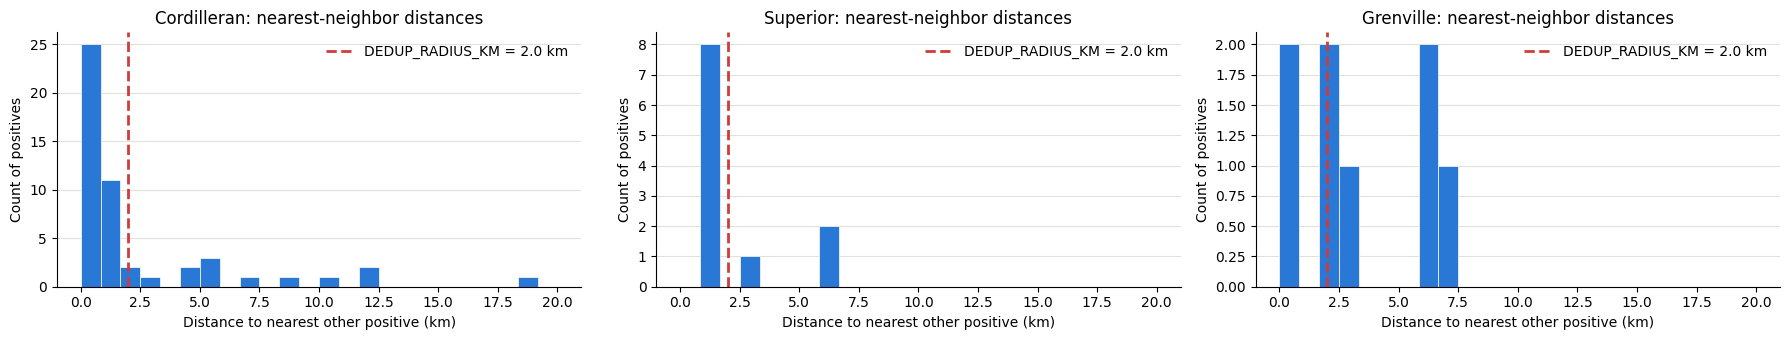

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, name in zip(axes, REGIONS):
    nn_km = NN_KM[name]
    bins = np.linspace(0, min(nn_km.max(), 20), 25)
    ax.hist(nn_km, bins=bins, color='#2a78d6', edgecolor='white', linewidth=0.5)
    ax.axvline(DEDUP_RADIUS_KM, color='#d03b3b', lw=2, ls='--',
               label=f'DEDUP_RADIUS_KM = {DEDUP_RADIUS_KM} km')
    ax.set_xlabel('Distance to nearest other positive (km)')
    ax.set_ylabel('Count of positives')
    ax.set_title(f'{name}: nearest-neighbor distances')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e1e0d9', lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## 4. Map of the Raw Positive Distribution

Both datasets, combined, plotted inside each region's outline and colored by
`source` (blue circle = `REE_Canada`, green triangle = `Parsa_2024`).
Visually dense clumps -- same-source or cross-source -- are candidates for
the same underlying deposit/district being listed more than once.


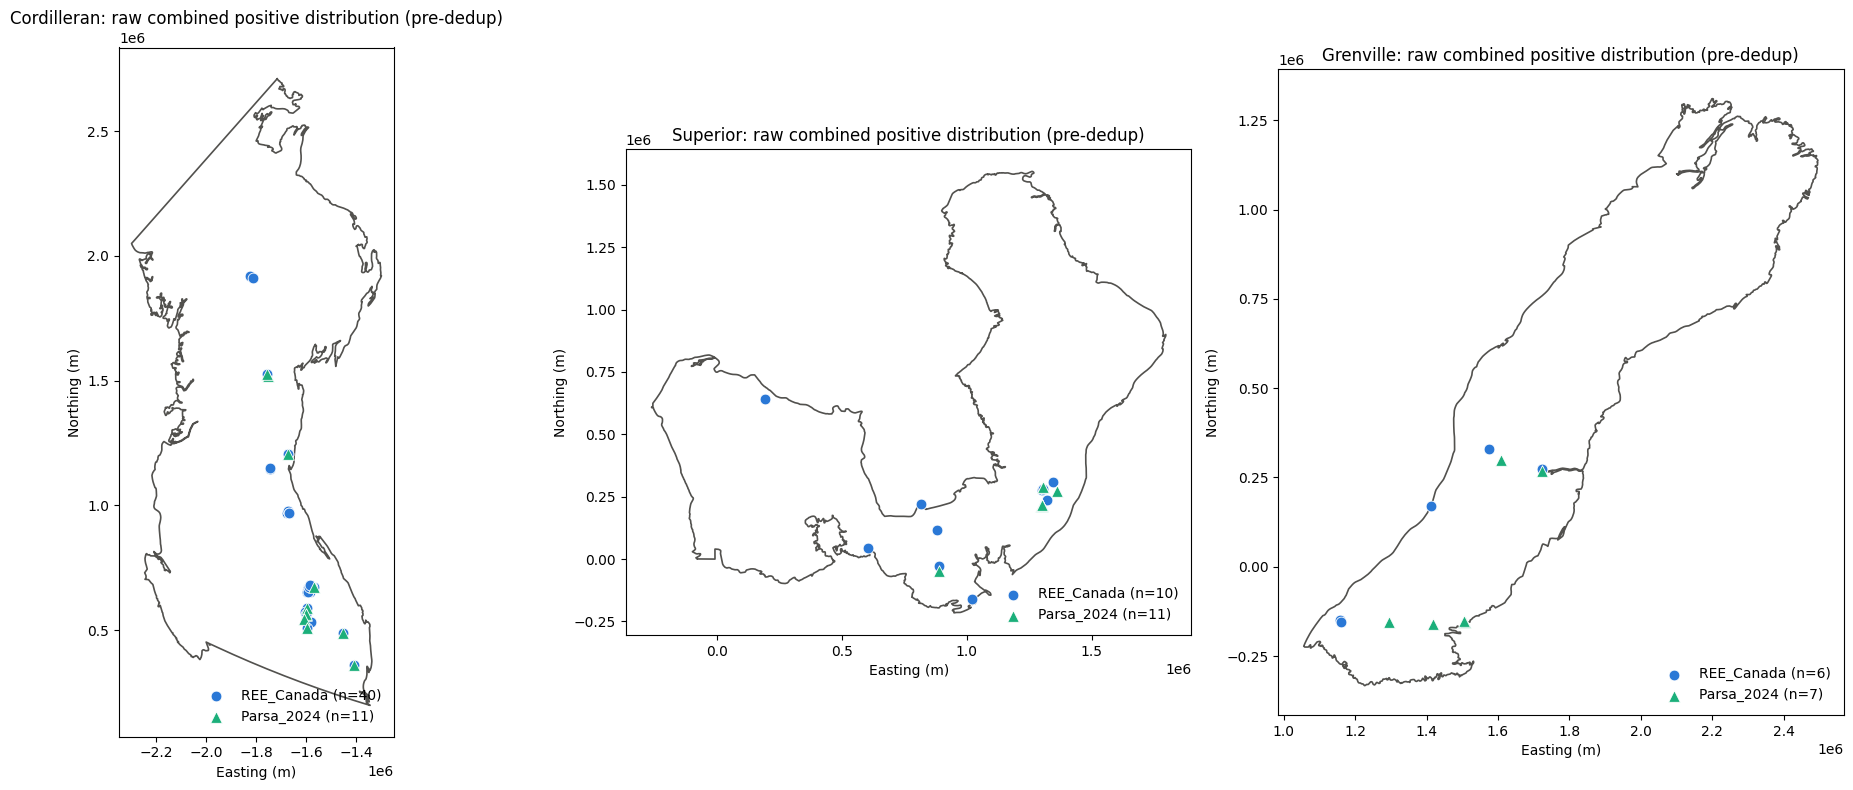

In [9]:
def draw_boundary(ax, bnd_proj, color=COLOR_BOUNDARY, lw=1.2):
    for geom in bnd_proj.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, '-', color=color, lw=lw, zorder=1)

BND_PROJ = {name: BOUNDARY[name].to_crs(PROJECTED_CRS) for name in REGIONS}

fig, axes = plt.subplots(1, 3, figsize=(19, 8))
for ax, name in zip(axes, REGIONS):
    coords = COORDS[name]
    is_canada = (POS_IN[name]['source'] == 'REE_Canada').values
    draw_boundary(ax, BND_PROJ[name])
    ax.scatter(coords[is_canada, 0], coords[is_canada, 1], s=60, c=COLOR_KEPT,
               edgecolors='white', linewidths=0.6, zorder=3,
               label=f'REE_Canada (n={is_canada.sum()})')
    ax.scatter(coords[~is_canada, 0], coords[~is_canada, 1], s=70, c=COLOR_PARSA,
               marker='^', edgecolors='white', linewidths=0.6, zorder=4,
               label=f'Parsa_2024 (n={(~is_canada).sum()})')

    ax.set_title(f'{name}: raw combined positive distribution (pre-dedup)')
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.set_aspect('equal')
    ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()


## 4a. Map by Deposit/Occurrence Type

Same combined pool, same points, colored instead by the 3-group confidence
classification (`dep_type`, from Section 2b): dark blue = `Deposit/Prospect`,
medium blue = `Showing`, light blue = `Occurrence` -- a single-hue sequential
ramp since this is an ordinal confidence scale, not an unordered category.


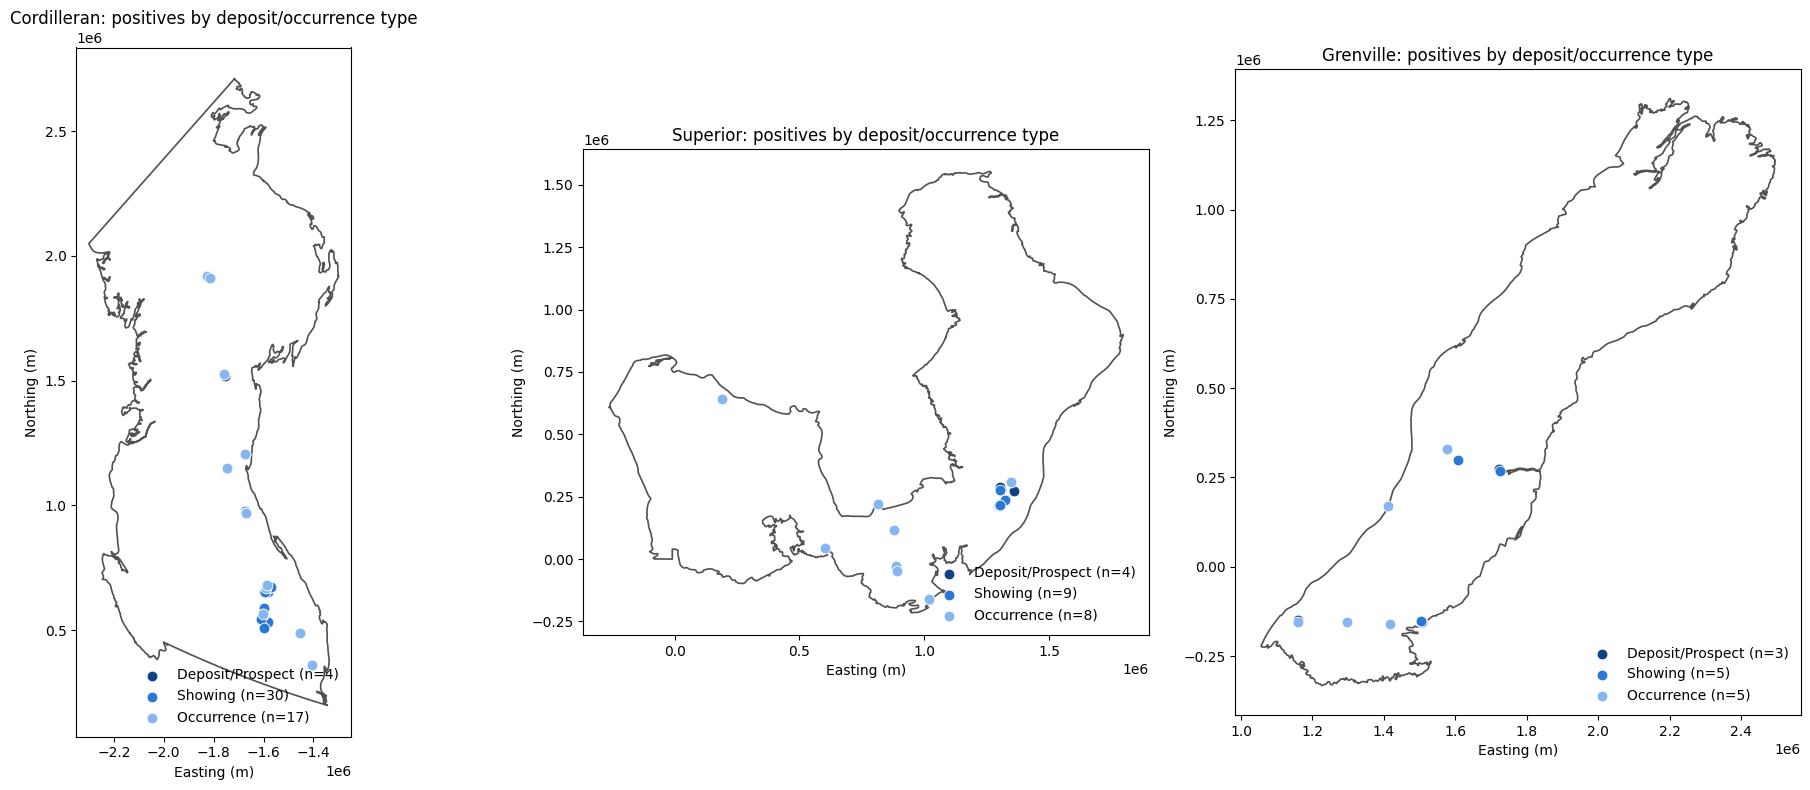

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 8))
for ax, name in zip(axes, REGIONS):
    coords = COORDS[name]
    dep_type = POS_IN[name]['dep_type'].values
    draw_boundary(ax, BND_PROJ[name])
    for t in TYPE_ORDER + ['Unknown']:
        mask = dep_type == t
        if mask.sum() == 0:
            continue
        ax.scatter(coords[mask, 0], coords[mask, 1], s=60, c=COLOR_TYPE[t],
                   edgecolors='white', linewidths=0.6, zorder=3,
                   label=f'{t} (n={mask.sum()})')
    ax.set_title(f'{name}: positives by deposit/occurrence type')
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.set_aspect('equal')
    ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()


## 5. Radius-Based Deduplication

Single-linkage clustering with a distance threshold of `DEDUP_RADIUS_KM`:
any two positives closer than the threshold join the same cluster, and the
merge is **transitive** (if A–B and B–C are both within radius, A/B/C all
collapse into one cluster even if A–C alone exceeds the radius — the
natural definition of "the same spot" for a chain of nearby records).

From each cluster we keep the point closest to the cluster's centroid (a
representative location) and drop the rest -- regardless of which dataset
the surviving point happens to come from. Run separately per region on the
**combined** `POS_IN` pool, so cross-dataset duplicates are merged too.


In [11]:
KEEP_MASK = {}
DEP_DEDUP = {}

for name in REGIONS:
    coords = COORDS[name]
    n = len(coords)
    dep_in = POS_IN[name].copy()

    Z = linkage(coords, method='single', metric='euclidean')
    cluster_ids = fcluster(Z, t=DEDUP_RADIUS_KM * 1000.0, criterion='distance')
    dep_in['cluster_id'] = cluster_ids

    keep_mask = np.zeros(n, dtype=bool)
    merge_report = []
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            keep_mask[idx[0]] = True
            continue
        centroid = coords[idx].mean(axis=0)
        d_to_centroid = np.linalg.norm(coords[idx] - centroid, axis=1)
        rep = idx[np.argmin(d_to_centroid)]
        keep_mask[rep] = True
        dropped = [i for i in idx if i != rep]
        merge_report.append({
            'kept': f"{dep_in.loc[rep, 'Name']} ({dep_in.loc[rep, 'source']})",
            'dropped': [f"{dep_in.loc[i, 'Name']} ({dep_in.loc[i, 'source']})" for i in dropped],
            'cluster_size': len(idx),
        })

    print(f'--- {name} ---')
    print(f'{n} positives -> {keep_mask.sum()} after dedup at {DEDUP_RADIUS_KM} km '
          f'(removed {n - keep_mask.sum()})')
    if merge_report:
        print('Merged clusters:')
        for m in merge_report:
            print(f"  kept {m['kept']!r:<30} <- dropped {m['dropped']}  (cluster size {m['cluster_size']})")
    else:
        print('No clusters exceeded 1 member at this radius -- nothing merged.')
    print()

    KEEP_MASK[name] = keep_mask
    DEP_DEDUP[name] = dep_in[keep_mask].drop(columns='cluster_id').reset_index(drop=True)


--- Cordilleran ---
51 positives -> 28 after dedup at 2.0 km (removed 23)
Merged clusters:
  kept 'Rar 7 (REE_Canada)'           <- dropped ['Rar 7 Kechika Yttrium (Parsa_2024)']  (cluster size 2)
  kept 'Rock Canyon Creek (REE_Canada)' <- dropped ['Rock Canyon Creek Deep Purple (Parsa_2024)']  (cluster size 2)
  kept 'Moose Creek Bow (Parsa_2024)' <- dropped ['Moose Creek (REE_Canada)']  (cluster size 2)
  kept 'Gum Creek (REE_Canada)'       <- dropped ['Hodgie Zone (REE_Canada)']  (cluster size 2)
  kept 'Bone Creek (REE_Canada)'      <- dropped ['Blue River (REE_Canada)', 'Fir (REE_Canada)', 'Mona (REE_Canada)', 'Upper Fir (REE_Canada)']  (cluster size 5)
  kept 'Lempriere (REE_Canada)'       <- dropped ['Mill (REE_Canada)', 'Verity (REE_Canada)']  (cluster size 3)
  kept 'Serpentine (REE_Canada)'      <- dropped ['Paradise (REE_Canada)']  (cluster size 2)
  kept 'Howard Creek (REE_Canada)'    <- dropped ['Howard Creek Carbonatite Top (Parsa_2024)']  (cluster size 2)
  kept 'AEG (RE

## 6. Before / After Map

Kept points in blue, removed (merged-away duplicates) in red, so you can see
exactly which points the radius cutoff is treating as redundant, per region.


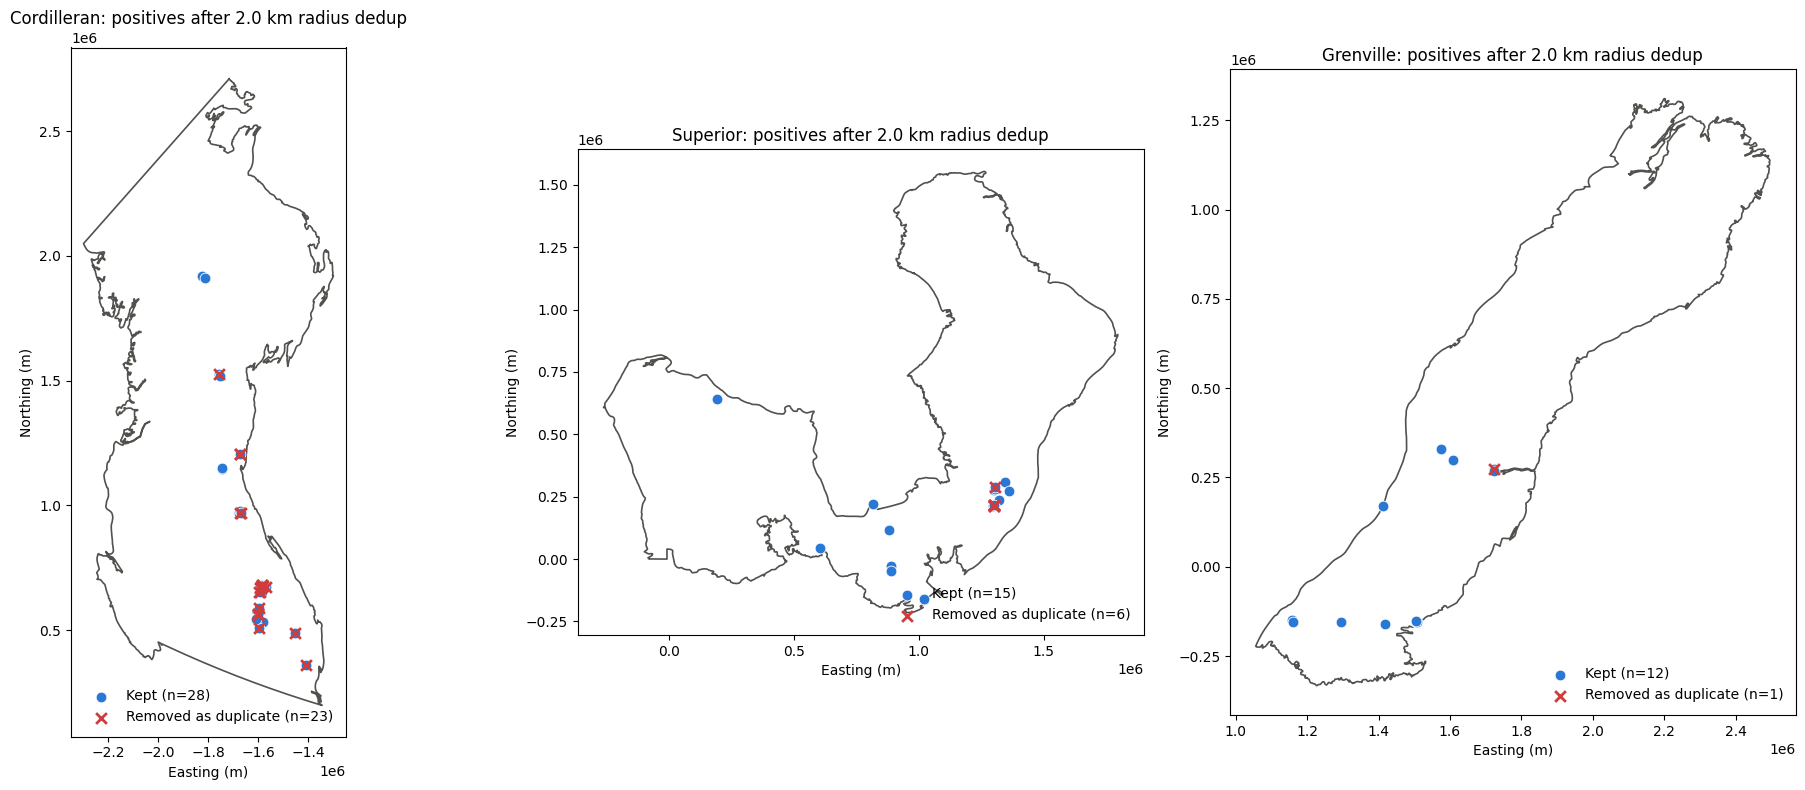

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 8))
for ax, name in zip(axes, REGIONS):
    coords = COORDS[name]
    keep_mask = KEEP_MASK[name]
    draw_boundary(ax, BND_PROJ[name])
    ax.scatter(coords[keep_mask, 0], coords[keep_mask, 1], s=60, c=COLOR_KEPT,
               edgecolors='white', linewidths=0.6, zorder=3,
               label=f'Kept (n={keep_mask.sum()})')
    ax.scatter(coords[~keep_mask, 0], coords[~keep_mask, 1], s=60, c=COLOR_REMOVED,
               marker='x', linewidths=2, zorder=4,
               label=f'Removed as duplicate (n={(~keep_mask).sum()})')
    ax.set_title(f'{name}: positives after {DEDUP_RADIUS_KM} km radius dedup')
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
    ax.set_aspect('equal')
    ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()


## 7. Save Deduplicated Positive Lists

Written next to this notebook, one CSV per region -- each row's `source`
column still records whether it came from `REE_Canada` or `Parsa_2024` (or,
for a merged cluster, whichever source the surviving representative point
came from). To use them in
`multiregion_rf_devnet_v3.ipynb`, either point `REGIONS[<name>]['dep']` at
the matching file, or filter the deposits loaded from the original CSV down
to these `Name` values before building features.


In [13]:
for name in REGIONS:
    out_path = f'{name}_REE_deposits_deduped_{DEDUP_RADIUS_KM}km.csv'
    DEP_DEDUP[name].to_csv(out_path, index=False)
    print(f'[{name}] saved {len(DEP_DEDUP[name])} deduplicated positives -> {out_path}')


[Cordilleran] saved 28 deduplicated positives -> Cordilleran_REE_deposits_deduped_2.0km.csv
[Superior] saved 15 deduplicated positives -> Superior_REE_deposits_deduped_2.0km.csv
[Grenville] saved 12 deduplicated positives -> Grenville_REE_deposits_deduped_2.0km.csv
